# 1. Load Dataset From Kaggel
  - Dataset Link: "https://www.kaggle.com/datasets/nikhilroxtomar/brain-tumor-segmentation?select=images"

In [ ]:
! pip -q install kagglehub

import kagglehub
# Download latest version
DATA_DIR = kagglehub.dataset_download("nikhilroxtomar/brain-tumor-segmentation")
print("Path to dataset files:", DATA_DIR)


Using Colab cache for faster access to the 'brain-tumor-segmentation' dataset.
Path to dataset files: /kaggle/input/brain-tumor-segmentation


In [ ]:
! pip install -q torchmetrics
! pip install -q torchsummary
! pip install -q albumentations

In [ ]:
! pip install -q torchsummary

# 2. Imports Libraries and Setup

In [ ]:
# 2.1 Imports
import os, glob, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split

import torch
import torchmetrics
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as tf
from torchsummary import summary

from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

# 2.2 Setup CUDA
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print('Cuda Available:', DEVICE)
print('GPU Name:', torch.cuda.get_device_name(0))


# 2.3 Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

IMG_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 60
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 7
THRESHOLD = 0.5

CHECKPOINT_PATH = "best_unet.pth"


Cuda Available: cuda
GPU Name: Tesla T4


In [ ]:

print('Folders Availabile:', os.listdir(DATA_DIR))

Folders Availabile: ['images', 'masks']


In [ ]:
DATA_ROOT= Path(DATA_DIR)

images_dir= DATA_ROOT / 'images'
mask_dir= DATA_ROOT / 'masks'

print(DATA_ROOT)
print(images_dir.exists())
print(mask_dir.exists())

/kaggle/input/brain-tumor-segmentation
True
True


In [ ]:
images= sorted(images_dir.glob('*'))
masks= sorted(mask_dir.glob('*'))

print('Total Images:',len(list(images)))
print('Total Masks:', len(list(masks)))

Total Images: 3064
Total Masks: 3064


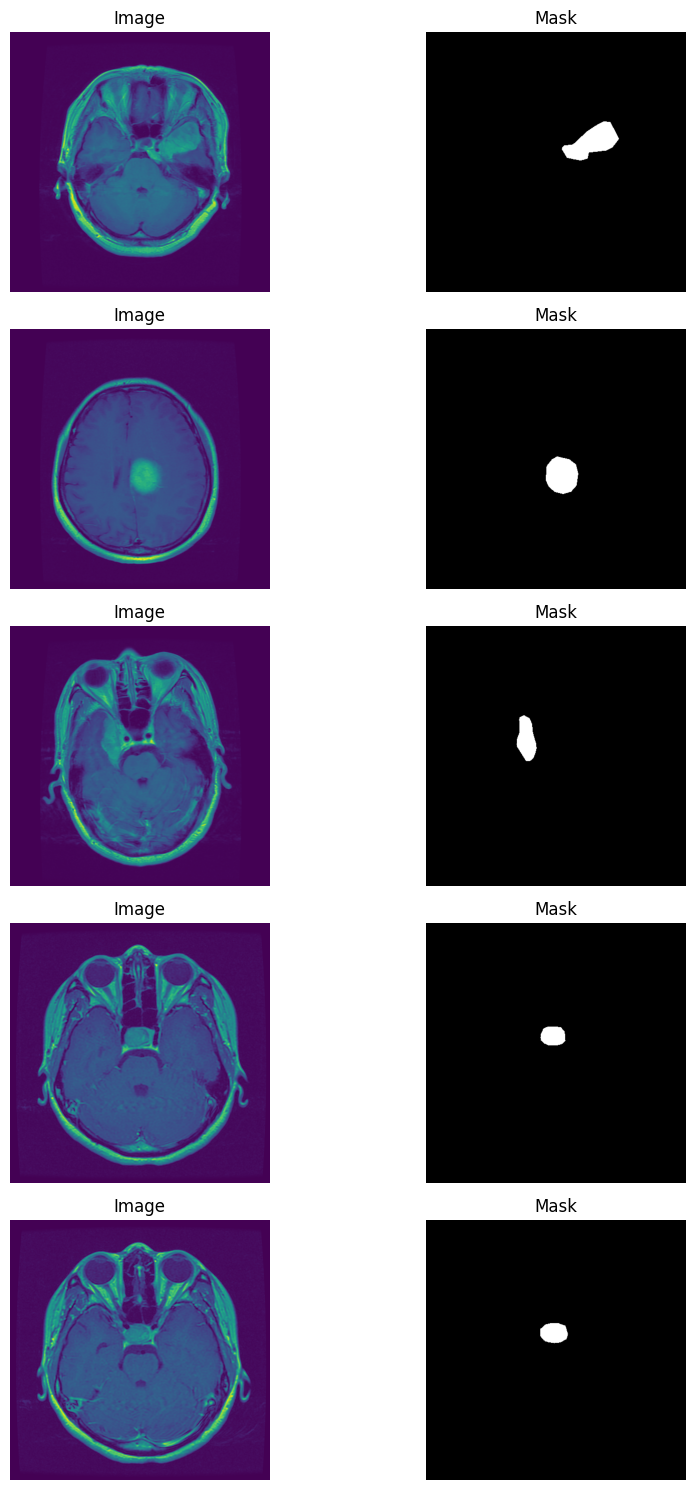

In [ ]:
plt.figure(figsize=(10, 15))

for i in range(5):
    image = Image.open(images[i])
    mask = Image.open(masks[i])

    plt.subplot(5, 2, 2*i + 1)
    plt.imshow(image)
    plt.title("Image")
    plt.axis("off")

    plt.subplot(5, 2, 2*i + 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 3. Dataset Class and Transforms

In [ ]:
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    A.Normalize(),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(),
    ToTensorV2()
])

In [ ]:
class BrainTumorDataset(Dataset):

    def __init__(self, image_paths, masks_dir, transform=None):
        self.image_paths = list(image_paths)
        self.masks_dir = Path(masks_dir)
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        # Get image and mask paths
        img_path = self.image_paths[idx]
        mask_path = self.masks_dir / img_path.name

        # Read image and mask
        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path).convert("L"))

        # Convert mask to binary
        mask = (mask > 0).astype(np.uint8)

        # Apply transformations
        if self.transform:
            augmented = self.transform(image=image, mask=mask)

            image = augmented["image"]
            mask = augmented["mask"]
        else:
            image = torch.from_numpy(
                image.astype(np.float32) / 255.0
            ).permute(2, 0, 1)

            mask = torch.from_numpy(mask)

        # Mask shape: (1, H, W)
        mask = mask.unsqueeze(0).float()

        return image, mask

In [ ]:
# Splite Data To Train/val/Test
image_paths = sorted(images_dir.glob("*"))

# Check image-mask matching
image_paths = [
    p for p in image_paths
    if (mask_dir / p.name).exists()
]

assert len(image_paths) > 0, "No matched image-mask pairs found!"

# Train: 70%, Remaining: 30%
train_paths, temp_paths = train_test_split(
    image_paths,
    test_size=0.30,
    random_state=SEED
)

# Validation: 15%, Test: 15%
val_paths, test_paths = train_test_split(
    temp_paths,
    test_size=0.50,
    random_state=SEED
)

print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))

Train: 2144
Validation: 460
Test: 460


In [ ]:
# Create Dataset
train_dataset = BrainTumorDataset(
    train_paths,
    mask_dir,
    transform=train_transform
)

val_dataset = BrainTumorDataset(
    val_paths,
    mask_dir,
    transform=val_transform
)

test_dataset = BrainTumorDataset(
    test_paths,
    mask_dir,
    transform=val_transform
)

print("Train Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Test Dataset:", len(test_dataset))

Train Dataset: 2144
Validation Dataset: 460
Test Dataset: 460


In [ ]:
# Data Loaders

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers= 0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [ ]:
images, masks = next(iter(train_loader))

print("Images Shape:", images.shape)
print("Masks Shape:", masks.shape)
print("Mask Values:", torch.unique(masks))

Images Shape: torch.Size([16, 3, 256, 256])
Masks Shape: torch.Size([16, 1, 256, 256])
Mask Values: tensor([0., 1.])


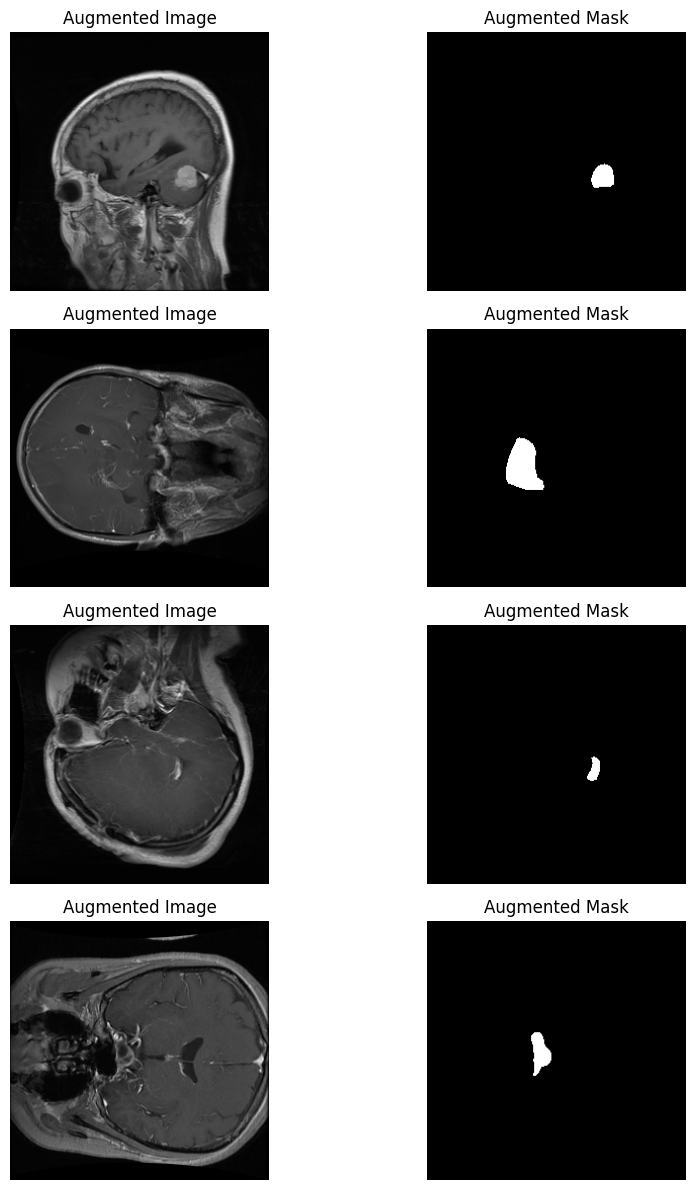

In [ ]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

plt.figure(figsize=(10, 12))

for i in range(4):

    image, mask = train_dataset[i]

    image = image.permute(1, 2, 0).numpy()
    image = (image * std + mean).clip(0, 1)

    mask = mask.squeeze().numpy()

    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(image)
    plt.title("Augmented Image")
    plt.axis("off")

    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Augmented Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 4. Build U-net Model
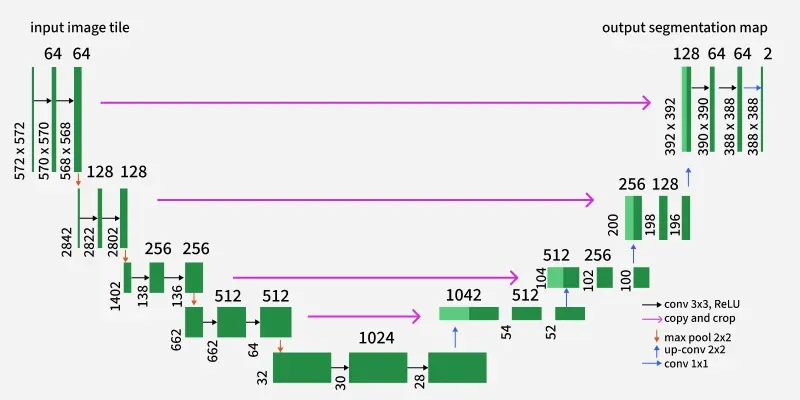

In [ ]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

In [ ]:
class UNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # Output Layer
        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + Skip Connections
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        # Raw logits
        return self.final_conv(d1)

In [ ]:
# Initialize Model
model = UNet(in_channels=3,out_channels=1).to(DEVICE)
print("Device:", DEVICE)
print(summary(model, input_size= (3, 256, 256)))

Device: cuda
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 256, 256]           1,792
       BatchNorm2d-2         [-1, 64, 256, 256]             128
              ReLU-3         [-1, 64, 256, 256]               0
            Conv2d-4         [-1, 64, 256, 256]          36,928
       BatchNorm2d-5         [-1, 64, 256, 256]             128
              ReLU-6         [-1, 64, 256, 256]               0
        DoubleConv-7         [-1, 64, 256, 256]               0
         MaxPool2d-8         [-1, 64, 128, 128]               0
            Conv2d-9        [-1, 128, 128, 128]          73,856
      BatchNorm2d-10        [-1, 128, 128, 128]             256
             ReLU-11        [-1, 128, 128, 128]               0
           Conv2d-12        [-1, 128, 128, 128]         147,584
      BatchNorm2d-13        [-1, 128, 128, 128]             256
             ReLU-14      

In [ ]:
class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = torch.sigmoid(logits)

        dims = (1, 2, 3)

        intersection = (probs * targets).sum(dim=dims)

        denominator = (
            probs.sum(dim=dims) +
            targets.sum(dim=dims)
        )

        dice = (
            2 * intersection + self.smooth
        ) / (denominator + self.smooth)

        return 1 - dice.mean()


class BCEDiceLoss(nn.Module):

    def __init__(self, bce_weight=0.5):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):

        bce_loss = self.bce(logits, targets)
        dice_loss = self.dice(logits, targets)

        return (
            self.bce_weight * bce_loss +
            (1 - self.bce_weight) * dice_loss
        )


criterion = BCEDiceLoss(bce_weight=0.5)

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
@torch.no_grad()
def calculate_metrics(logits, targets, threshold=0.5):

    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    dims = (1, 2, 3)
    eps = 1e-7

    intersection = (preds * targets).sum(dim=dims)

    pred_sum = preds.sum(dim=dims)
    target_sum = targets.sum(dim=dims)

    dice = (
        2 * intersection + eps
    ) / (pred_sum + target_sum + eps)

    union = pred_sum + target_sum - intersection

    iou = (
        intersection + eps
    ) / (union + eps)

    return dice.mean().item(), iou.mean().item()

In [ ]:
from contextlib import nullcontext

USE_AMP = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

def run_epoch(model, loader, criterion, optimizer=None):

    is_train = optimizer is not None

    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_samples = 0

    phase = "Training" if is_train else "Validation"

    progress = tqdm(loader, desc=phase, leave=False)

    for images, masks in progress:

        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, masks)

            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

        dice, iou = calculate_metrics(
            outputs.detach().float(),
            masks,
            threshold=THRESHOLD
        )

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_dice += dice * batch_size
        total_iou += iou * batch_size
        total_samples += batch_size

        progress.set_postfix(
            loss=f"{total_loss / total_samples:.4f}",
            dice=f"{total_dice / total_samples:.4f}",
            iou=f"{total_iou / total_samples:.4f}"
        )

    return {
        "loss": total_loss / total_samples,
        "dice": total_dice / total_samples,
        "iou": total_iou / total_samples
    }

In [ ]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],
    "lr": []
}

best_dice = -1.0
patience_counter = 0

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")

    # Training
    train_metrics = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # Validation
    val_metrics = run_epoch(
        model,
        val_loader,
        criterion
    )

    # Learning rate scheduling
    scheduler.step(val_metrics["loss"])

    # Save history
    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])

    history["train_dice"].append(train_metrics["dice"])
    history["val_dice"].append(val_metrics["dice"])

    history["train_iou"].append(train_metrics["iou"])
    history["val_iou"].append(val_metrics["iou"])

    history["lr"].append(
        optimizer.param_groups[0]["lr"]
    )

    # Epoch summary
    print(
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f}"
    )

    print(
        f"Train Dice: {train_metrics['dice']:.4f} | "
        f"Val Dice: {val_metrics['dice']:.4f}"
    )

    print(
        f"Train IoU: {train_metrics['iou']:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f}"
    )

    # Save best model
    if val_metrics["dice"] > best_dice:

        best_dice = val_metrics["dice"]
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_dice": best_dice
            },
            CHECKPOINT_PATH
        )

        print(f"Best Model Saved! Dice: {best_dice:.4f}")

    else:
        patience_counter += 1

        print(
            f"No improvement: "
            f"{patience_counter}/{PATIENCE}"
        )

    # Early stopping
    if patience_counter >= PATIENCE:
        print("Early Stopping Triggered!")
        break

print(f"\nTraining Completed! Best Val Dice: {best_dice:.4f}")


Epoch [1/60]


Training:   0%|          | 0/134 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

Train Loss: 0.6572 | Val Loss: 0.5990
Train Dice: 0.2400 | Val Dice: 0.4272
Train IoU: 0.1706 | Val IoU: 0.3301
Best Model Saved! Dice: 0.4272

Epoch [2/60]


Training:   0%|          | 0/134 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

... (114 outputs left out)

Train Loss: 0.0972 | Val Loss: 0.1158
Train Dice: 0.8364 | Val Dice: 0.8024
Train IoU: 0.7511 | Val IoU: 0.7178
No improvement: 6/7

Epoch [41/60]


Training:   0%|          | 0/134 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

Train Loss: 0.0957 | Val Loss: 0.1154
Train Dice: 0.8397 | Val Dice: 0.8033
Train IoU: 0.7538 | Val IoU: 0.7187
No improvement: 7/7
Early Stopping Triggered!

Training Completed! Best Val Dice: 0.8082


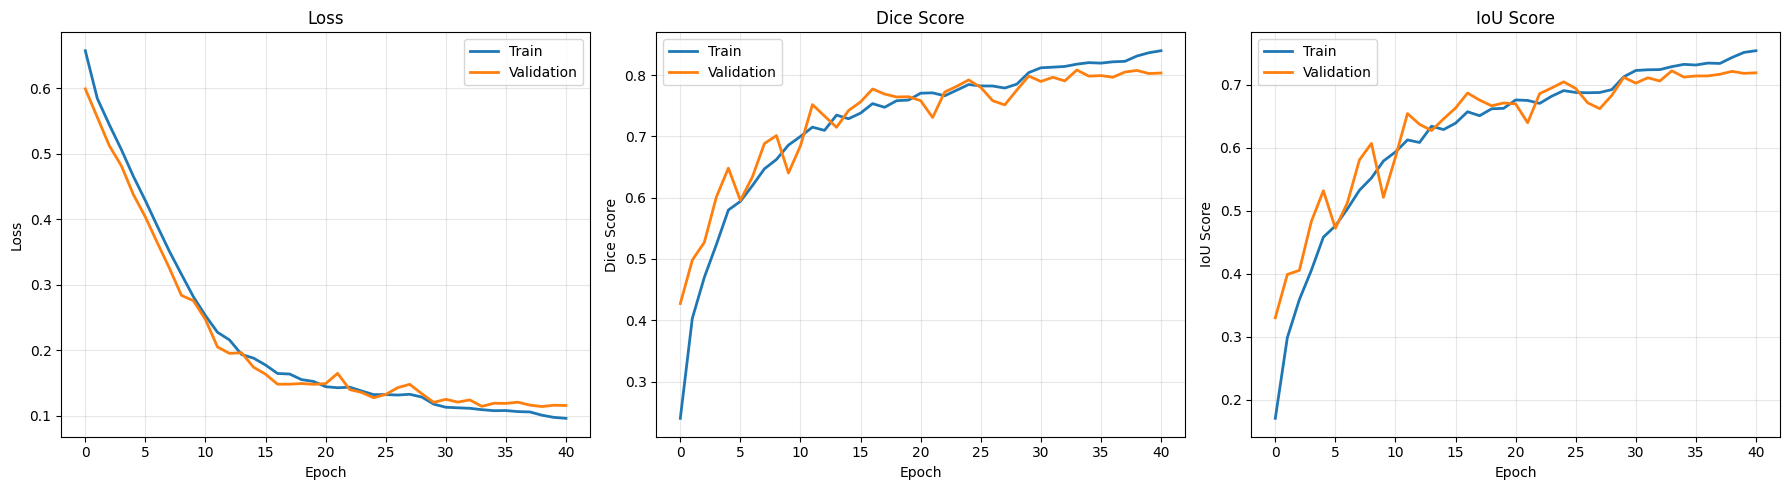

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("loss", "Loss"),
    ("dice", "Dice Score"),
    ("iou", "IoU Score")
]

for ax, (metric, title) in zip(axes, metrics):

    ax.plot(
        history[f"train_{metric}"],
        label="Train",
        linewidth=2
    )

    ax.plot(
        history[f"val_{metric}"],
        label="Validation",
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best Model Loaded!")
print("Best Validation Dice:", checkpoint["best_dice"])

Best Model Loaded!
Best Validation Dice: 0.8081905204316844


In [ ]:
test_metrics = run_epoch(
    model,
    test_loader,
    criterion
)

print("\nFinal Test Results")
print("-" * 30)

print(f"Test Loss : {test_metrics['loss']:.4f}")
print(f"Test Dice : {test_metrics['dice']:.4f}")
print(f"Test IoU  : {test_metrics['iou']:.4f}")

Validation:   0%|          | 0/29 [00:00<?, ?it/s]


Final Test Results
------------------------------
Test Loss : 0.1206
Test Dice : 0.7951
Test IoU  : 0.7075


In [ ]:
def visualize_predictions(model, dataset, n=5, threshold=0.5):

    model.eval()

    indices = random.sample(
        range(len(dataset)),
        min(n, len(dataset))
    )

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    fig, axes = plt.subplots(
        len(indices), 4,
        figsize=(16, 4 * len(indices)),
        squeeze=False
    )

    for i, idx in enumerate(indices):

        image, mask = dataset[idx]

        # Prediction
        with torch.inference_mode():
            logits = model(image.unsqueeze(0).to(DEVICE))
            probs = torch.sigmoid(logits)
            pred = (probs > threshold).float()

        pred = pred.squeeze().cpu().numpy()
        mask = mask.squeeze().cpu().numpy()

        # Denormalize image
        img = image.permute(1, 2, 0).cpu().numpy()
        img = (img * std + mean).clip(0, 1)

        # Calculate Dice Score
        intersection = (pred * mask).sum()
        dice = (2 * intersection + 1e-7) / (
            pred.sum() + mask.sum() + 1e-7
        )

        # Original
        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Original MRI")

        # Ground Truth
        axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Ground Truth")

        # Prediction
        axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title(f"Prediction | Dice: {dice:.3f}")

        # Overlay
        axes[i, 3].imshow(img)
        axes[i, 3].imshow(
            np.ma.masked_where(pred == 0, pred),
            cmap="Reds",
            alpha=0.5,
            vmin=0,
            vmax=1
        )
        axes[i, 3].set_title("Prediction Overlay")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
visualize_predictions(
    model=model,
    dataset=test_dataset,
    n=10,
    threshold=0.5
)

NameError: name 'visualize_predictions' is not defined